In [1]:
import sys, os
sys.path.insert(0, os.getcwd())

import json
import pickle
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.patches as mpatches
import jax
import jax.numpy as jnp
from sklearn.decomposition import PCA

from network import LeakyRNN
from task import generate_trials, load_params as load_task_params
from utils.fixed_points import find_fixed_points, get_phase_step, phase_label
%matplotlib widget

In [2]:
# ── Checkpoint to analyse ─────────────────────────────────────────────────────
RESULTS_DIR = Path(os.environ.get('TONE_RESULTS_DIR', 'results'))
ckpt_path = RESULTS_DIR / 'transfer_pure_to_harmonic/context+sensory/harmonic_0_lr5e-06_bs128_noise0.5_nrnn128/checkpoint.pkl'
task_list = ['pure', 'harmonic', 'wn']

# ── Trial phases to analyse — same convention as fixed_point_pure_hct.ipynb ───
#   'fixation'  — last pre-stim step (fixation=1, no stimulus, context on)
#   'pulse_on'  — during the N-th pulse, input held constant
#   'stim_off'  — end of stimulus (silence resumes)
phases = [
    ('fixation', None),
    ('pulse_on',  1),
    ('pulse_on',  2),
    ('pulse_on',  3),
    ('pulse_on',  4),
    ('pulse_on',  5),
    ('pulse_on',  6),
    ('pulse_on',  7),
    ('pulse_on',  8),
    ('stim_off',  None),
]

# ── Bifurcation sweep ─────────────────────────────────────────────────────────
n_alpha    = 21     # alpha values from 0 (pure) to 1 (HCT), inclusive
n_trials   = 128    # trials per task for initial hidden states
n_iters    = 8000   # Adam steps per FP search
lr         = 1e-2
tol        = 1e-6   # q-value convergence threshold
unique_tol = 1e-2   # L2 deduplication radius

In [3]:
# ── Load checkpoint and config ────────────────────────────────────────────────
with open(ckpt_path.parent / 'config.json') as f:
    config = json.load(f)

hp          = config['training']
task_params = config['task_params']
task_list   = config.get('task_list', config.get('tasks', task_list))

with open(ckpt_path, 'rb') as f:
    ckpt = pickle.load(f)

params = ckpt['params']
dt          = ckpt.get('dt',       task_params['timing']['dt'])
stim_on     = ckpt.get('stim_on',  config.get('stim_on',
                         int(task_params['timing']['pre_stim_dur_ms'] / dt)))
stim_off    = ckpt.get('stim_off', config.get('stim_off',
                         stim_on + task_params['timing']['n_pulses'] *
                         max(1, int(np.ceil(task_params['timing']['pulse_dur_ms'] / dt)))))
pulse_steps = config.get('pulse_steps',
              max(1, int(np.ceil(task_params['timing']['pulse_dur_ms'] / dt))))
n_rnn = hp['model']['n_rnn']
rnn_alpha = dt / hp['model']['tau']

out_dir = ckpt_path.parent / f'checkpoint_{ckpt["step"]}'
out_dir.mkdir(exist_ok=True)
print(f'Output dir: {out_dir}')

# ── Build model ───────────────────────────────────────────────────────────────
model = LeakyRNN(
    n_rnn     = n_rnn,
    n_out     = 1,
    alpha     = rnn_alpha,
    sigma_rec = hp['model']['sigma_rec'],
    sigma_x   = hp['model']['sigma_x'],
)

# ── Run pure and harmonic trials (no noise) ───────────────────────────────────
rng = np.random.default_rng(1)
trial_pure = generate_trials('pure',     task_list, mode='test',
                             batch_size=n_trials, rng=rng)
trial_hct  = generate_trials('harmonic', task_list, mode='test',
                             batch_size=n_trials, rng=rng)

def _run(trial):
    xs = jnp.array(trial.x)
    _, hs = model.apply({'params': params}, xs,
                        noise_input=False, noise_rec=False,
                        rngs={'noise': jax.random.PRNGKey(0)})
    return np.array(hs)   # (tdim, batch, n_rnn)

hs_pure = _run(trial_pure)
hs_hct  = _run(trial_hct)

go_pure   = trial_pure.is_go
nogo_pure = ~go_pure
go_hct    = trial_hct.is_go
nogo_hct  = ~go_hct

print(f'Loaded: {ckpt_path}  (step {ckpt["step"]})')
print(f'n_rnn={n_rnn}  dt={dt}ms  stim_on={stim_on}  stim_off={stim_off}  pulse_steps={pulse_steps}')
print(f'Pure:     {go_pure.sum()} Go, {nogo_pure.sum()} No-Go')
print(f'Harmonic: {go_hct.sum()} Go, {nogo_hct.sum()} No-Go')

Output dir: C:\Users\zhixi\Documents\data\results\tone_generalize\transfer_pure_to_harmonic\context+sensory\harmonic_0_lr5e-06_bs128_noise0.5_nrnn128\checkpoint_10000
Loaded: C:\Users\zhixi\Documents\data\results\tone_generalize\transfer_pure_to_harmonic\context+sensory\harmonic_0_lr5e-06_bs128_noise0.5_nrnn128\checkpoint.pkl  (step 10000)
n_rnn=128  dt=10ms  stim_on=50  stim_off=90  pulse_steps=5
Pure:     64 Go, 64 No-Go
Harmonic: 64 Go, 64 No-Go


In [4]:
# ── Fit PCA on hidden states pooled across both tasks ─────────────────────────
hs_all  = np.concatenate([hs_pure, hs_hct], axis=1)  # (tdim, 2*n_trials, n_rnn)
pca     = PCA(n_components=3)
pca.fit(hs_all.reshape(-1, n_rnn))
var_exp = pca.explained_variance_ratio_ * 100
print(f'PC1={var_exp[0]:.1f}%  PC2={var_exp[1]:.1f}%  PC3={var_exp[2]:.1f}%')

PC1=90.6%  PC2=5.8%  PC3=1.3%


In [5]:
# ── Sweep alpha and find fixed points at each phase ───────────────────────────
# alpha=0 → pure-tone input   alpha=1 → HCT input
# x_blend(alpha) = (1-alpha)*x_pure + alpha*x_hct
#
# Initial hidden states: pooled from both tasks to sample the full state space.
# Fixed-point finding uses the blended frozen input at each alpha.

STIM_ON_PHASES = {'stim_on', 'pulse_on'}
alphas = np.linspace(0.0, 1.0, n_alpha)

bifur_results = {}  # key -> {alpha: {'go': fp_dict, 'nogo': fp_dict, ...}}

for phase, pulse_num in phases:
    t_step = get_phase_step(phase, stim_on, stim_off, pulse_steps,
                            pulse_num=pulse_num if pulse_num else 2)
    key = phase_label(phase, pulse_num)
    print(f'\n══ {key}  (t_step={t_step}) ══')

    # Frozen inputs at this phase step for each task and condition
    n_freq = trial_pure.n_freq
    def _x(trial, mask):
        i = np.where(mask)[0][0]
        x = trial.x[t_step, i, :].copy()
        if phase in STIM_ON_PHASES:
            x[n_freq] = 1.0   # force fixation on during stim
        return x

    x_pure_go   = _x(trial_pure, go_pure)
    x_pure_nogo = _x(trial_pure, nogo_pure)
    x_hct_go    = _x(trial_hct,  go_hct)
    x_hct_nogo  = _x(trial_hct,  nogo_hct)

    # Pool initial hidden states from both tasks
    h_go_inits   = np.concatenate([hs_pure[t_step, go_pure,   :],
                                    hs_hct[t_step,  go_hct,   :]], axis=0)
    h_nogo_inits = np.concatenate([hs_pure[t_step, nogo_pure, :],
                                    hs_hct[t_step,  nogo_hct, :]], axis=0)

    phase_data = {}
    for a in alphas:
        x_go_blend   = (1.0 - a) * x_pure_go   + a * x_hct_go
        x_nogo_blend = (1.0 - a) * x_pure_nogo + a * x_hct_nogo

        fp_go   = find_fixed_points(params, x_go_blend,   h_go_inits,
                                    rnn_alpha, n_iters=n_iters, lr=lr,
                                    tol=tol, unique_tol=unique_tol, verbose=False)
        fp_nogo = find_fixed_points(params, x_nogo_blend, h_nogo_inits,
                                    rnn_alpha, n_iters=n_iters, lr=lr,
                                    tol=tol, unique_tol=unique_tol, verbose=False)

        n_go_s   = int(fp_go['is_stable'].sum())
        n_nogo_s = int(fp_nogo['is_stable'].sum())
        print(f'  alpha={a:.2f}  go: {len(fp_go["h"])} FP ({n_go_s} stbl)  '
              f'nogo: {len(fp_nogo["h"])} FP ({n_nogo_s} stbl)')

        phase_data[float(a)] = {
            'go':   fp_go,   'nogo': fp_nogo,
            'x_go': x_go_blend, 'x_nogo': x_nogo_blend,
        }

    bifur_results[key] = phase_data

print('\nDone.')


══ fixation  (t_step=49) ══
  alpha=0.00  go: 1 FP (1 stbl)  nogo: 1 FP (1 stbl)
  alpha=0.05  go: 1 FP (0 stbl)  nogo: 1 FP (0 stbl)
  alpha=0.10  go: 0 FP (0 stbl)  nogo: 0 FP (0 stbl)
  alpha=0.15  go: 0 FP (0 stbl)  nogo: 0 FP (0 stbl)
  alpha=0.20  go: 0 FP (0 stbl)  nogo: 0 FP (0 stbl)
  alpha=0.25  go: 0 FP (0 stbl)  nogo: 0 FP (0 stbl)
  alpha=0.30  go: 0 FP (0 stbl)  nogo: 0 FP (0 stbl)
  alpha=0.35  go: 0 FP (0 stbl)  nogo: 0 FP (0 stbl)
  alpha=0.40  go: 0 FP (0 stbl)  nogo: 0 FP (0 stbl)
  alpha=0.45  go: 0 FP (0 stbl)  nogo: 0 FP (0 stbl)
  alpha=0.50  go: 0 FP (0 stbl)  nogo: 0 FP (0 stbl)
  alpha=0.55  go: 0 FP (0 stbl)  nogo: 0 FP (0 stbl)
  alpha=0.60  go: 0 FP (0 stbl)  nogo: 0 FP (0 stbl)
  alpha=0.65  go: 0 FP (0 stbl)  nogo: 0 FP (0 stbl)
  alpha=0.70  go: 0 FP (0 stbl)  nogo: 0 FP (0 stbl)
  alpha=0.75  go: 0 FP (0 stbl)  nogo: 0 FP (0 stbl)
  alpha=0.80  go: 0 FP (0 stbl)  nogo: 0 FP (0 stbl)
  alpha=0.85  go: 0 FP (0 stbl)  nogo: 0 FP (0 stbl)
  alpha=0.90  go:

C:\Users\zhixi\AppData\Local\Temp\ipykernel_1536\1917933701.py:71: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


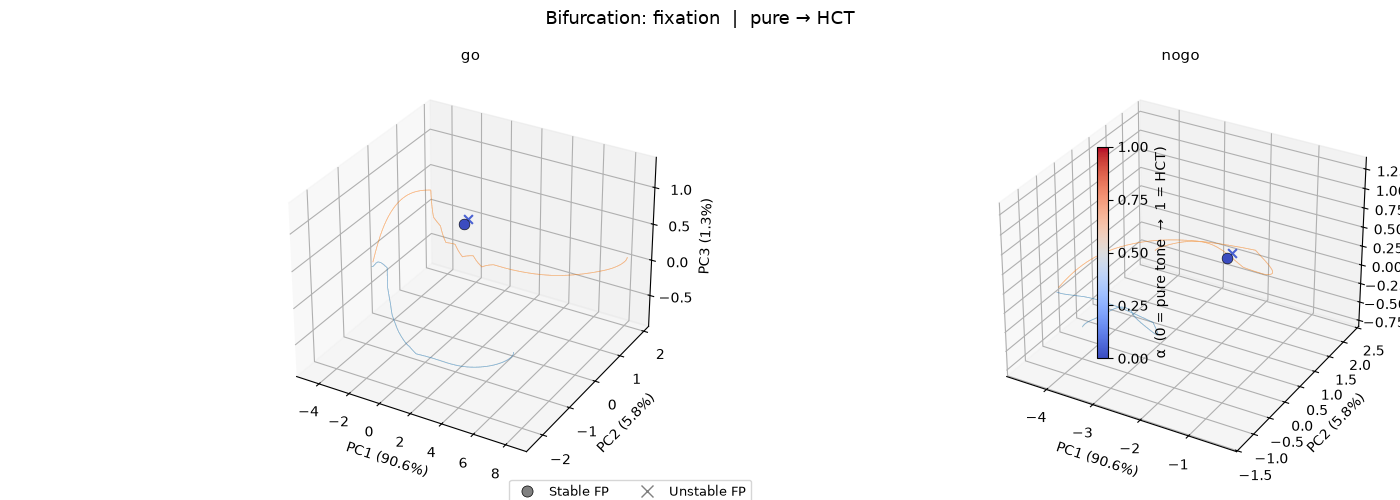

C:\Users\zhixi\AppData\Local\Temp\ipykernel_1536\1917933701.py:71: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


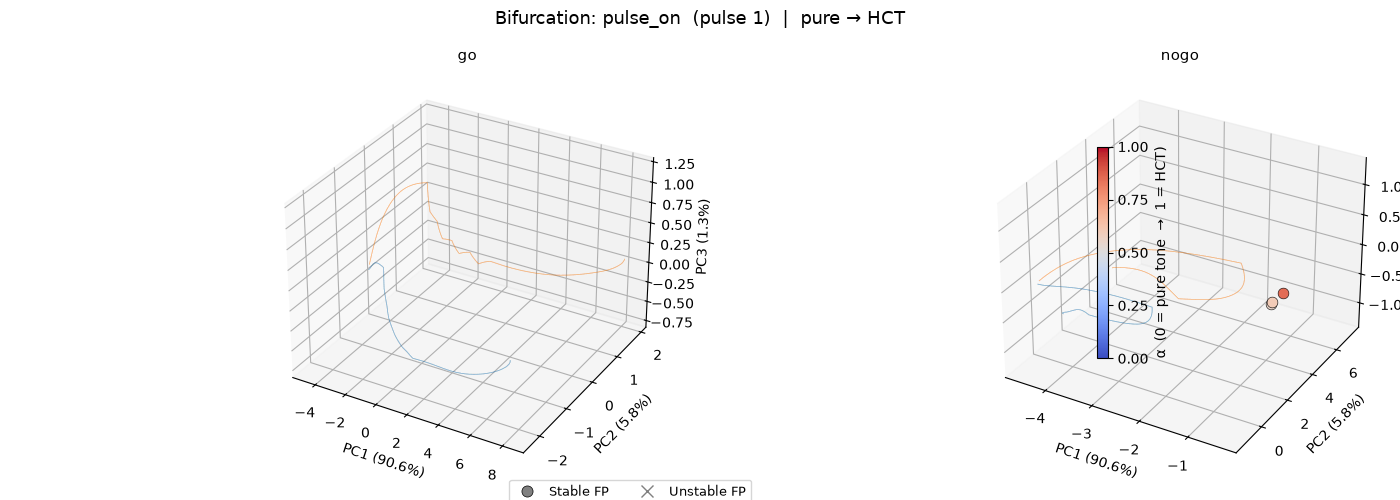

C:\Users\zhixi\AppData\Local\Temp\ipykernel_1536\1917933701.py:71: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


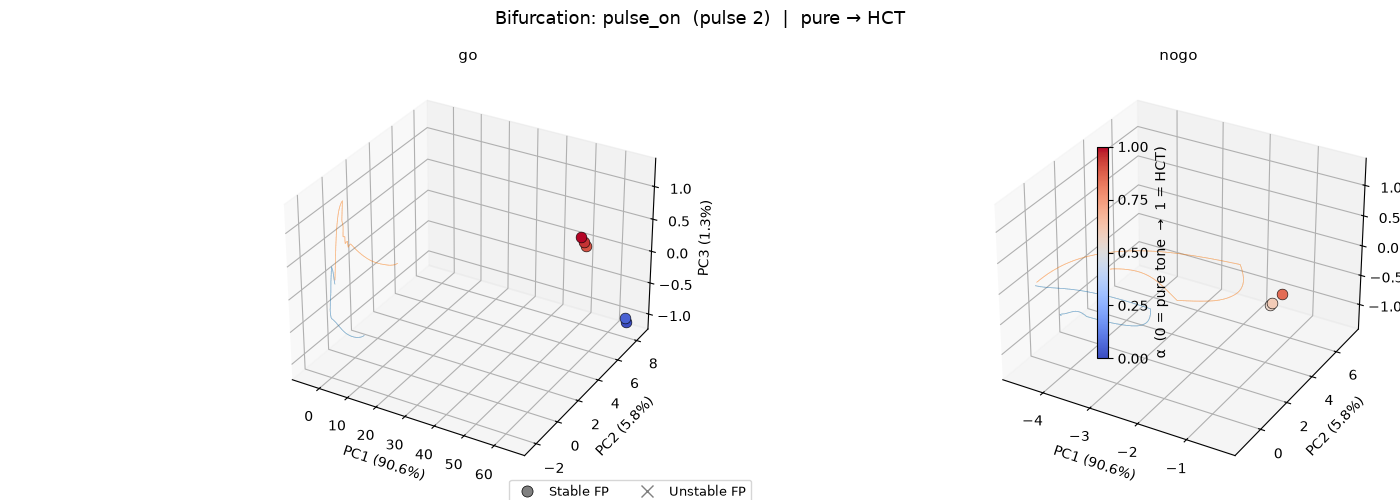

C:\Users\zhixi\AppData\Local\Temp\ipykernel_1536\1917933701.py:71: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


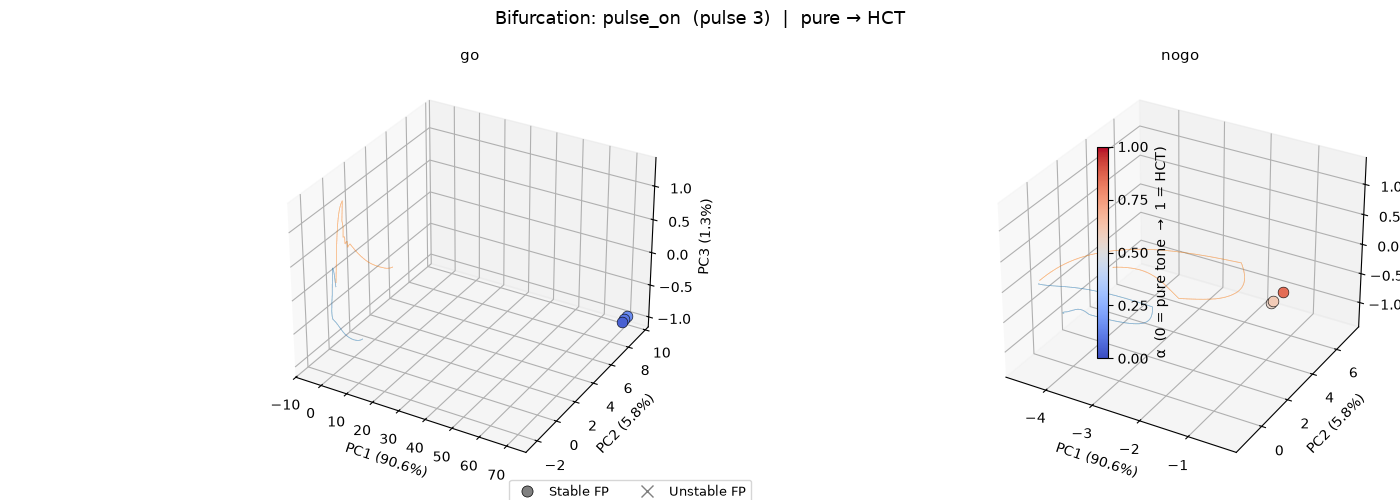

C:\Users\zhixi\AppData\Local\Temp\ipykernel_1536\1917933701.py:71: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


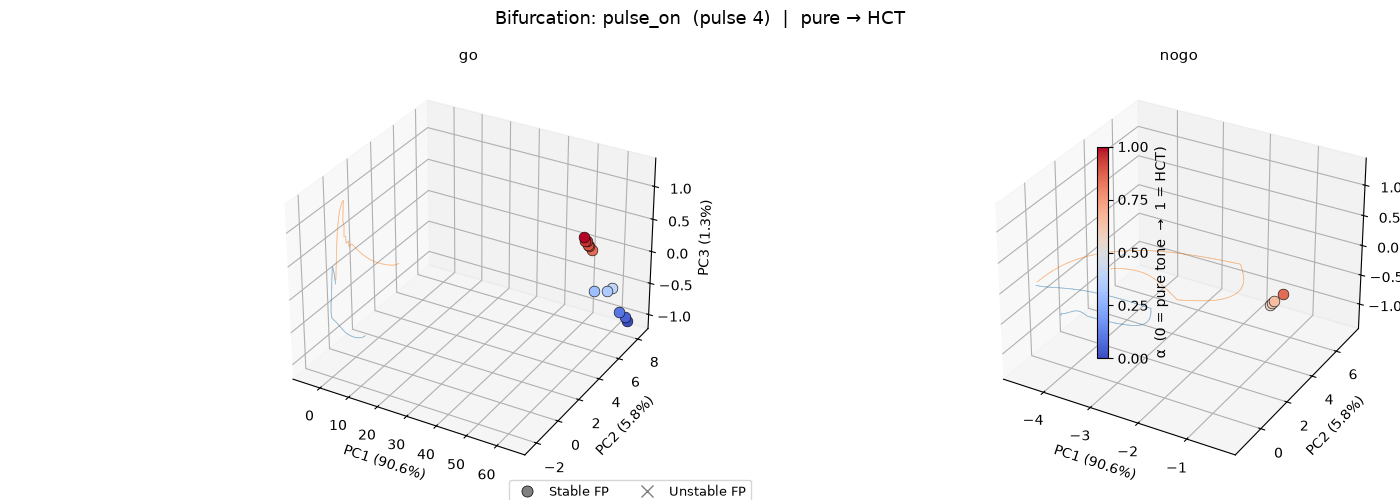

C:\Users\zhixi\AppData\Local\Temp\ipykernel_1536\1917933701.py:71: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


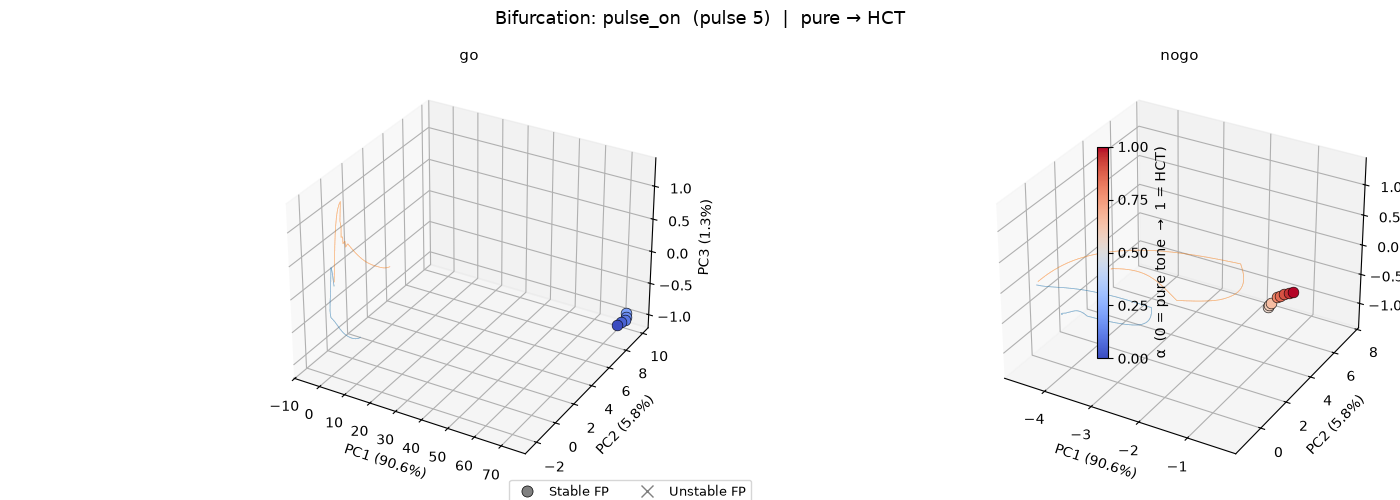

C:\Users\zhixi\AppData\Local\Temp\ipykernel_1536\1917933701.py:71: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


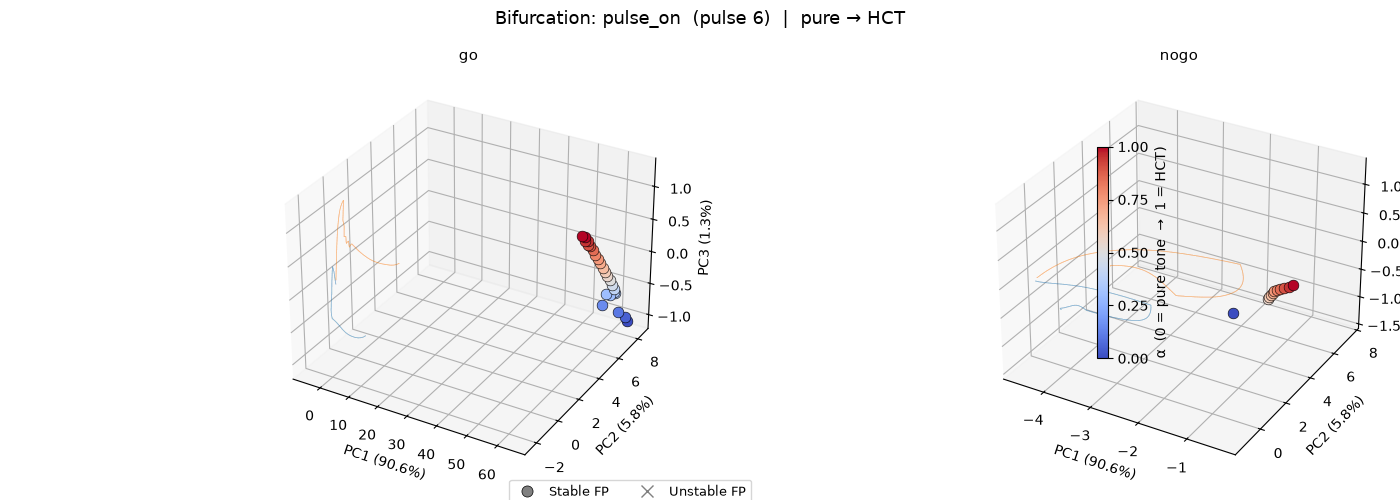

C:\Users\zhixi\AppData\Local\Temp\ipykernel_1536\1917933701.py:71: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


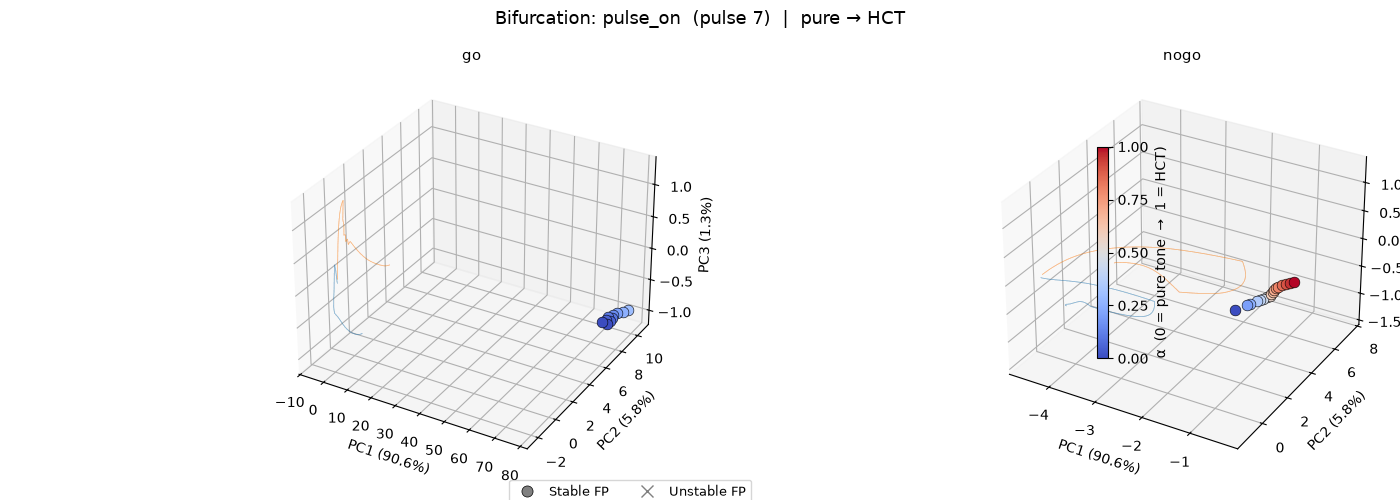

C:\Users\zhixi\AppData\Local\Temp\ipykernel_1536\1917933701.py:71: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


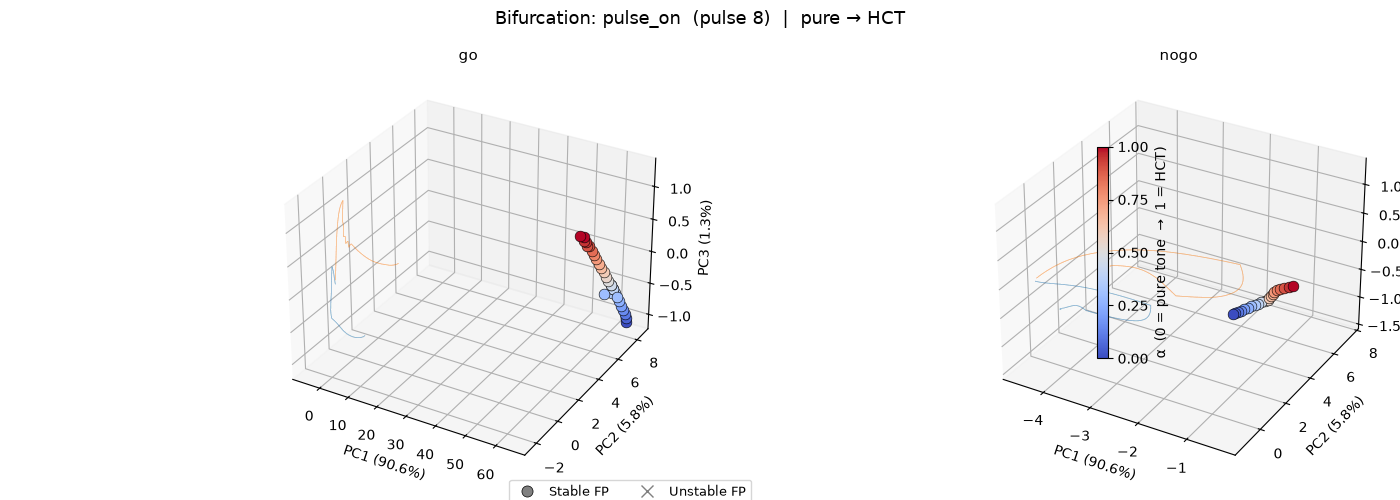

C:\Users\zhixi\AppData\Local\Temp\ipykernel_1536\1917933701.py:71: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


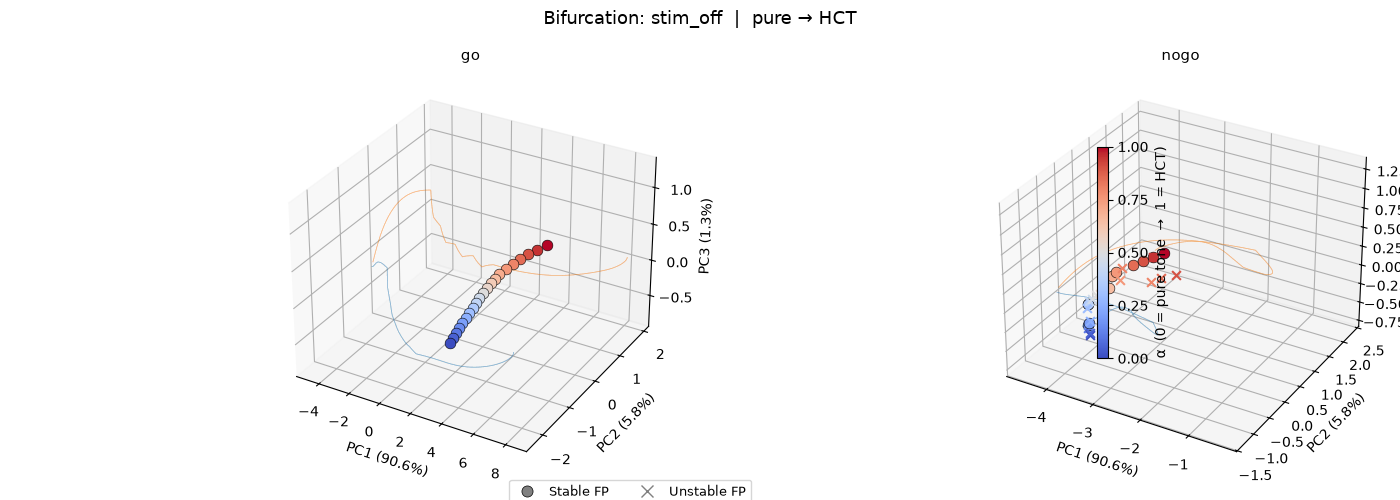

In [6]:
# ── 3D scatter: fixed-point positions coloured by alpha ───────────────────────
# Each panel: one trial phase × one condition (Go / No-Go)
# Color encodes alpha (0=pure blue → 1=HCT red); marker encodes stability.

cmap_a  = plt.cm.coolwarm
norm_a  = mcolors.Normalize(0.0, 1.0)

for phase, pulse_num in phases:
    key = phase_label(phase, pulse_num)
    if key not in bifur_results:
        continue
    phase_data = bifur_results[key]
    sorted_alphas = sorted(phase_data.keys())

    fig, axes = plt.subplots(1, 2, figsize=(14, 5),
                             subplot_kw={'projection': '3d'})

    for ax, (cond, mask_pure, mask_hct, hs_src, col_bg) in zip(
        axes,
        [('go',   go_pure, go_hct,   hs_pure, 'tab:blue'),
         ('nogo', nogo_pure, nogo_hct, hs_hct, 'tab:orange')]):

        # Faint background trajectories from both tasks
        for i in list(np.where(mask_pure)[0])[:12]:
            p = pca.transform(hs_pure[:, i, :])
            ax.plot(p[:, 0], p[:, 1], p[:, 2], color='tab:blue',
                    alpha=0.06, lw=0.5)
        for i in list(np.where(mask_hct)[0])[:12]:
            p = pca.transform(hs_hct[:, i, :])
            ax.plot(p[:, 0], p[:, 1], p[:, 2], color='tab:orange',
                    alpha=0.06, lw=0.5)

        # Fixed points: coloured by alpha, marker = stability
        for a in sorted_alphas:
            fp  = phase_data[a][cond]
            if len(fp['h']) == 0:
                continue
            col    = cmap_a(norm_a(a))
            p      = pca.transform(fp['h'])
            stable = fp['is_stable']
            if stable.any():
                ax.scatter(p[stable, 0], p[stable, 1], p[stable, 2],
                           s=60, marker='o', color=col,
                           edgecolors='k', linewidths=0.4, depthshade=False, zorder=5)
            if (~stable).any():
                ax.scatter(p[~stable, 0], p[~stable, 1], p[~stable, 2],
                           s=40, marker='x', color=col, depthshade=False, zorder=5)

        ax.set_title(f'{cond}', fontsize=11)
        ax.set_xlabel(f'PC1 ({var_exp[0]:.1f}%)', labelpad=3)
        ax.set_ylabel(f'PC2 ({var_exp[1]:.1f}%)', labelpad=3)
        ax.set_zlabel(f'PC3 ({var_exp[2]:.1f}%)', labelpad=3)

    sm = plt.cm.ScalarMappable(cmap=cmap_a, norm=norm_a)
    sm.set_array([])
    cb = fig.colorbar(sm, ax=axes.tolist(), shrink=0.55, pad=0.06,
                      label='α  (0 = pure tone  →  1 = HCT)')
    cb.set_ticks([0, 0.25, 0.5, 0.75, 1.0])

    legend_h = [
        plt.Line2D([0],[0], marker='o', color='gray', linestyle='None',
                   ms=8, mec='k', mew=0.5, label='Stable FP'),
        plt.Line2D([0],[0], marker='x', color='gray', linestyle='None',
                   ms=8, label='Unstable FP'),
    ]
    fig.legend(handles=legend_h, loc='lower center', ncol=2, fontsize=9,
               bbox_to_anchor=(0.45, -0.02))

    fname = key.replace(' ', '_').replace('(','').replace(')','').strip()
    fig.suptitle(f'Bifurcation: {key}  |  pure → HCT', fontsize=13)
    plt.tight_layout()
    plt.savefig(out_dir / f'bifur_3d_{fname}_{ckpt["step"]}.png',
                dpi=150, bbox_inches='tight')
    plt.show()

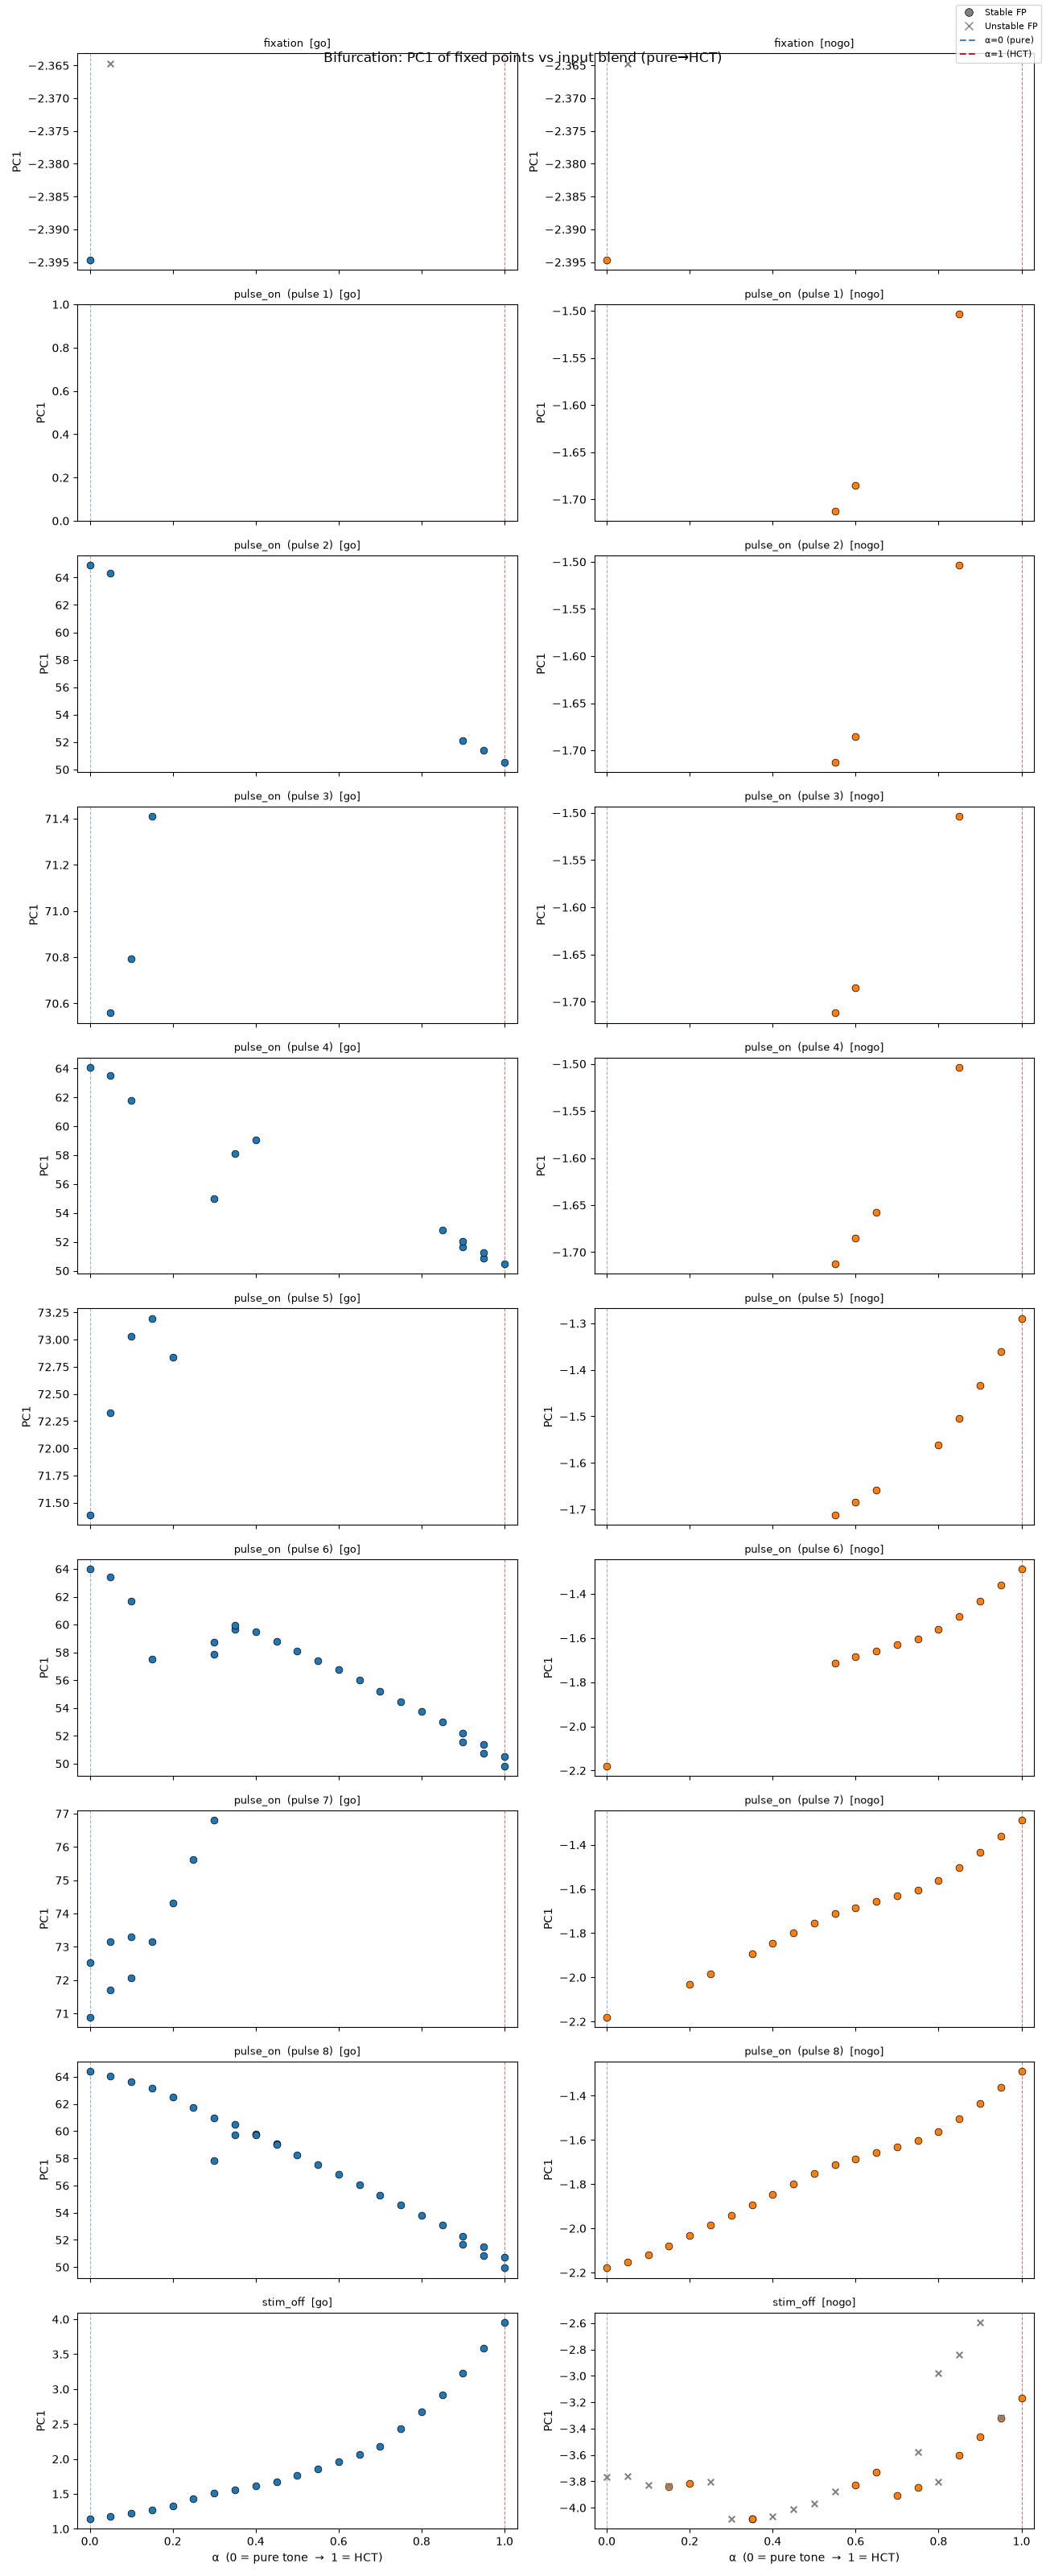

In [7]:
# ── 1D bifurcation diagram: PC1 and PC2 of fixed points vs alpha ──────────────
# Each row = one phase; columns = Go, NoGo.
# Solid dots = stable FPs; x = unstable FPs.
# Bifurcation points appear where branches appear/disappear.

n_phases = len(phases)
fig, axes = plt.subplots(n_phases, 2,
                          figsize=(13, 3.2 * n_phases),
                          sharex=True)
if n_phases == 1:
    axes = axes[np.newaxis, :]

for row, (phase, pulse_num) in enumerate(phases):
    key = phase_label(phase, pulse_num)
    if key not in bifur_results:
        continue
    phase_data  = bifur_results[key]
    sorted_a    = sorted(phase_data.keys())

    for col, cond in enumerate(['go', 'nogo']):
        ax = axes[row, col]
        col_c = 'tab:blue' if cond == 'go' else 'tab:orange'

        for a in sorted_a:
            fp = phase_data[a][cond]
            if len(fp['h']) == 0:
                continue
            p      = pca.transform(fp['h'])
            stable = fp['is_stable']
            if stable.any():
                ax.scatter([a] * stable.sum(), p[stable, 0],
                           s=40, marker='o', color=col_c,
                           edgecolors='k', linewidths=0.5, zorder=4)
            if (~stable).any():
                ax.scatter([a] * (~stable).sum(), p[~stable, 0],
                           s=30, marker='x', color='gray', zorder=4)

        ax.axvline(0.0, color='steelblue',   lw=0.8, ls='--', alpha=0.6)
        ax.axvline(1.0, color='firebrick',   lw=0.8, ls='--', alpha=0.6)
        ax.set_xlim(-0.03, 1.03)
        ax.set_ylabel('PC1')
        ax.set_title(f'{key}  [{cond}]', fontsize=9)
        if row == n_phases - 1:
            ax.set_xlabel('α  (0 = pure tone  →  1 = HCT)')

# Shared legend
legend_h = [
    plt.Line2D([0],[0], marker='o', color='gray', linestyle='None',
               ms=7, mec='k', mew=0.5, label='Stable FP'),
    plt.Line2D([0],[0], marker='x', color='gray', linestyle='None',
               ms=7, label='Unstable FP'),
    plt.Line2D([0],[0], color='steelblue', ls='--', label='α=0 (pure)'),
    plt.Line2D([0],[0], color='firebrick', ls='--', label='α=1 (HCT)'),
]
fig.legend(handles=legend_h, loc='upper right', fontsize=8, bbox_to_anchor=(1.0, 1.0))
fig.suptitle('Bifurcation: PC1 of fixed points vs input blend (pure→HCT)',
             fontsize=12)
plt.tight_layout()
plt.savefig(out_dir / f'bifur_1d_{ckpt["step"]}.png', dpi=150, bbox_inches='tight')
plt.show()

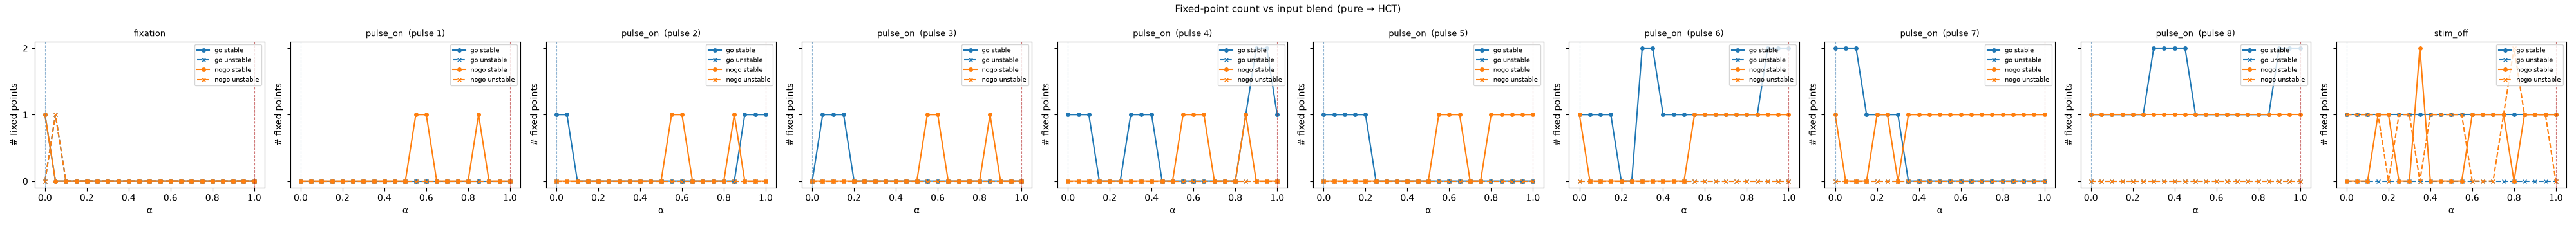

In [8]:
# ── Fixed-point count vs alpha — quick summary ────────────────────────────────
fig, axes = plt.subplots(1, len(phases), figsize=(4 * len(phases), 3.5), sharey=True)
if len(phases) == 1:
    axes = [axes]

for ax, (phase, pulse_num) in zip(axes, phases):
    key = phase_label(phase, pulse_num)
    if key not in bifur_results:
        continue
    phase_data = bifur_results[key]
    sorted_a   = sorted(phase_data.keys())

    for cond, col_c in [('go', 'tab:blue'), ('nogo', 'tab:orange')]:
        n_stable   = [phase_data[a][cond]['is_stable'].sum()    for a in sorted_a]
        n_unstable = [(~phase_data[a][cond]['is_stable']).sum() for a in sorted_a]
        ax.plot(sorted_a, n_stable,   '-o', color=col_c, ms=4, label=f'{cond} stable')
        ax.plot(sorted_a, n_unstable, '--x', color=col_c, ms=4, label=f'{cond} unstable')

    ax.axvline(0, color='steelblue', lw=0.8, ls='--', alpha=0.6)
    ax.axvline(1, color='firebrick', lw=0.8, ls='--', alpha=0.6)
    ax.set_xlabel('α')
    ax.set_ylabel('# fixed points')
    ax.set_title(key, fontsize=9)
    ax.yaxis.get_major_locator().set_params(integer=True)
    ax.legend(fontsize=7, loc='upper right')

fig.suptitle('Fixed-point count vs input blend (pure → HCT)', fontsize=11)
plt.tight_layout()
plt.savefig(out_dir / f'bifur_fp_count_{ckpt["step"]}.png', dpi=150, bbox_inches='tight')
plt.show()